# MT8 – Yes/No Audio Classification

**Course:** Digital Speech Processing

**Instructor:** Dr. Khalooei

**Student:** Anas Raad Radih Alaasam

**Student ID:** 404131083

**Email:** anas.r.r.alaasam@gmail.com

## Introduction

In this mini-task, I investigate audio classification using the YESNO dataset available through TorchAudio.

My objective is to train and evaluate four different classifiers, including a Support Vector Machine (SVM) and a Neural Network, and compare their performance.

I will first explore the audio recordings, examine the sample rate and labels, and visualize the waveforms and spectrograms. I will then prepare the audio data, extract relevant features, train the classifiers, and evaluate their performance.

In [ ]:
%pip install -q numpy pandas matplotlib scipy scikit-learn librosa soundfile

In [ ]:
import sys
import torch

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

try:
    import torchaudio
    print("TorchAudio version:", torchaudio.__version__)
    print("YESNO dataset available:", hasattr(torchaudio.datasets, "YESNO"))
except Exception as e:
    print("TorchAudio error:", type(e).__name__, str(e))

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch version: 2.14.1+cpu
CUDA available: False
TorchAudio version: 2.11.0+cpu
YESNO dataset available: True


In [ ]:
from pathlib import Path
import torchaudio

data_path = Path("/content/YESNO_Dataset")

data_path.mkdir(parents=True, exist_ok=True)

dataset = torchaudio.datasets.YESNO(
    root=str(data_path),
    download=True
)

print("Dataset loaded successfully.")
print("Number of recordings:", len(dataset))

waveform, sample_rate, labels = dataset[0]

print("\nFirst Recording Information")
print("Waveform shape:", waveform.shape)
print("Sample rate:", sample_rate)
print("Labels:", labels)
print("Number of labels:", len(labels))
print("Duration (seconds):", waveform.shape[-1] / sample_rate)

100%|██████████| 4.49M/4.49M [00:01<00:00, 2.82MB/s]


Dataset loaded successfully.
Number of recordings: 60

First Recording Information
Waveform shape: torch.Size([1, 50800])
Sample rate: 8000
Labels: [0, 0, 0, 0, 1, 1, 1, 1]
Number of labels: 8
Duration (seconds): 6.35


## Audio Signal Visualization

I successfully downloaded the YESNO dataset using TorchAudio. The dataset contains 60 audio recordings.

I examined the first recording and found that it contains 50,800 samples, recorded at a sampling rate of 8,000 Hz, with a duration of 6.35 seconds.

The recording contains eight binary labels representing a sequence of Yes and No responses.

In this step, I visualize the waveform and spectrogram to examine the temporal structure and frequency characteristics of the speech signal.

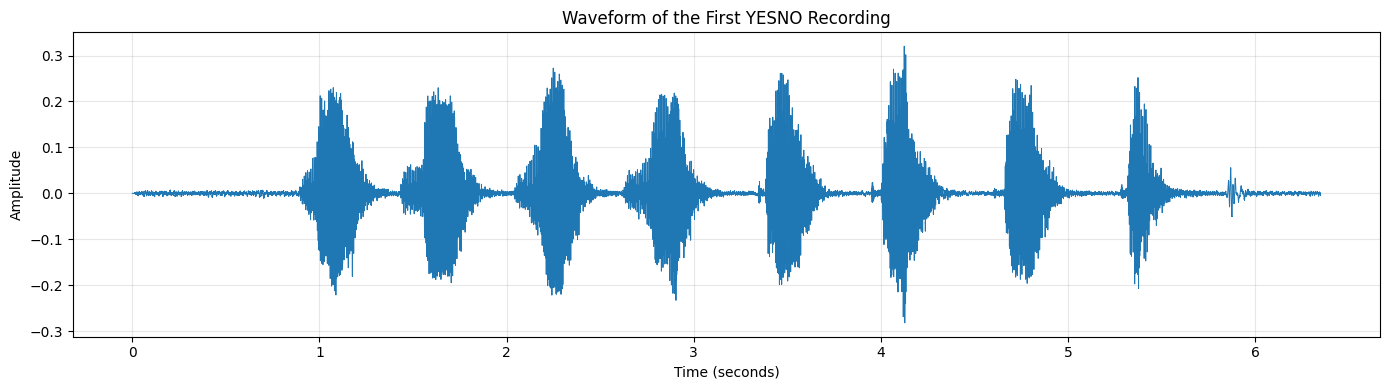

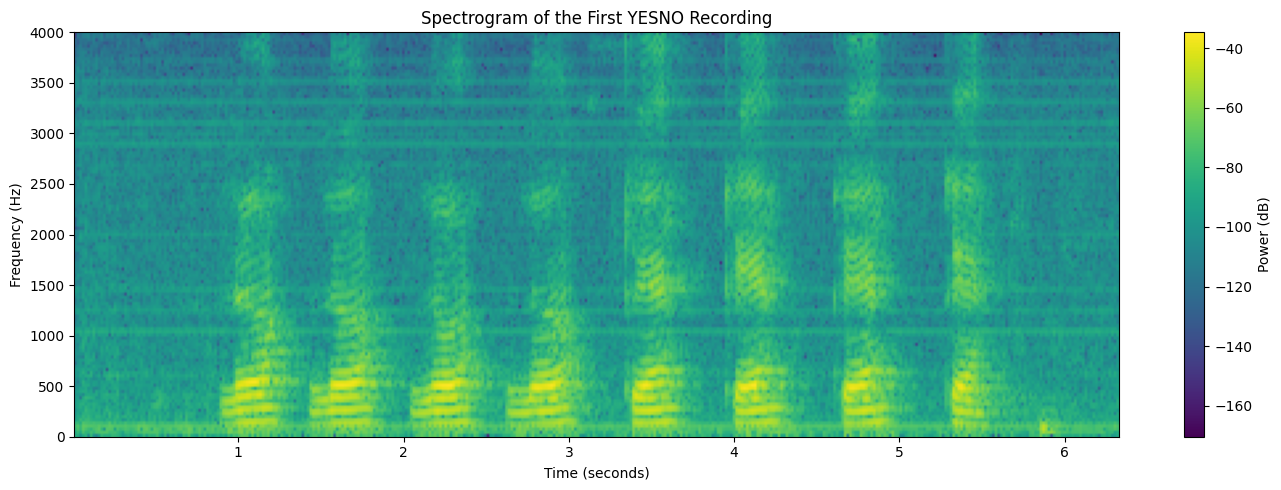

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

signal = waveform.squeeze().numpy()

time_axis = np.arange(len(signal)) / sample_rate

plt.figure(figsize=(14, 4))
plt.plot(time_axis, signal, linewidth=0.7)
plt.title("Waveform of the First YESNO Recording")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))

plt.specgram(
    signal,
    NFFT=256,
    Fs=sample_rate,
    noverlap=128,
    cmap="viridis"
)

plt.title("Spectrogram of the First YESNO Recording")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Power (dB)")
plt.ylim(0, sample_rate / 2)
plt.tight_layout()
plt.show()

## Speech Segmentation

I used a short-time energy threshold to locate word regions within the YESNO recordings. My initial configuration detected eight regions in 55 of the 60 recordings. I then tested less restrictive parameters and obtained eight detected regions in 59 recordings. Detecting the correct number of regions does not independently verify the word boundaries or labels.

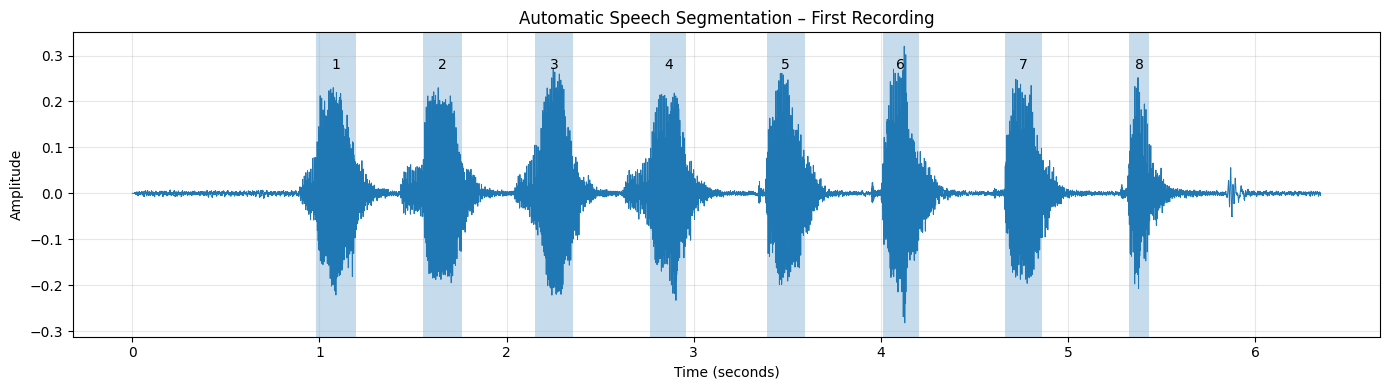

Detected segments: 8
Expected segments: 8
Segment 1: 0.983s – 1.193s
Segment 2: 1.553s – 1.764s
Segment 3: 2.150s – 2.356s
Segment 4: 2.767s – 2.960s
Segment 5: 3.389s – 3.594s
Segment 6: 4.011s – 4.204s
Segment 7: 4.666s – 4.859s
Segment 8: 5.324s – 5.435s


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_closing, binary_opening, median_filter

def detect_speech_segments(
    waveform,
    sample_rate,
    frame_ms=20,
    threshold_ratio=0.08,
    min_duration=0.10,
    min_silence=0.08
):
    signal = waveform.squeeze().numpy()

    frame_length = max(1, int(sample_rate * frame_ms / 1000))

    smoothed_energy = np.convolve(
        signal ** 2,
        np.ones(frame_length) / frame_length,
        mode="same"
    )

    threshold = threshold_ratio * np.max(smoothed_energy)

    speech_mask = smoothed_energy > threshold

    silence_samples = max(1, int(min_silence * sample_rate))

    speech_mask = binary_closing(
        speech_mask,
        structure=np.ones(silence_samples)
    )

    min_samples = max(1, int(min_duration * sample_rate))

    speech_mask = binary_opening(
        speech_mask,
        structure=np.ones(min_samples)
    )

    transitions = np.diff(
        np.concatenate(([0], speech_mask.astype(int), [0]))
    )

    starts = np.where(transitions == 1)[0]
    ends = np.where(transitions == -1)[0]

    segments = list(zip(starts, ends))

    return segments, smoothed_energy, threshold


segments, energy, threshold = detect_speech_segments(
    waveform,
    sample_rate
)

signal = waveform.squeeze().numpy()
time_axis = np.arange(len(signal)) / sample_rate

plt.figure(figsize=(14, 4))

plt.plot(time_axis, signal, linewidth=0.7)

for i, (start, end) in enumerate(segments):
    plt.axvspan(
        start / sample_rate,
        end / sample_rate,
        alpha=0.25,
        label="Detected Speech" if i == 0 else None
    )

    plt.text(
        (start + end) / (2 * sample_rate),
        0.27,
        str(i + 1),
        ha="center"
    )

plt.title("Automatic Speech Segmentation – First Recording")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Detected segments:", len(segments))
print("Expected segments:", len(labels))

for i, (start, end) in enumerate(segments):
    print(
        f"Segment {i+1}: "
        f"{start/sample_rate:.3f}s – "
        f"{end/sample_rate:.3f}s"
    )

In [ ]:
import pandas as pd
import numpy as np

segmentation_results = []
segmented_recordings = {}

for recording_id in range(len(dataset)):

    audio, sr, recording_labels = dataset[recording_id]

    detected_segments, _, _ = detect_speech_segments(
        audio,
        sr
    )

    expected = len(recording_labels)
    detected = len(detected_segments)

    segmentation_results.append({
        "Recording": recording_id,
        "Expected": expected,
        "Detected": detected,
        "Match": detected == expected
    })

    segmented_recordings[recording_id] = detected_segments

segmentation_df = pd.DataFrame(segmentation_results)

print("Total recordings:", len(segmentation_df))
print("Correct segment counts:", segmentation_df["Match"].sum())
print("Incorrect segment counts:", (~segmentation_df["Match"]).sum())

print("\nDistribution of detected segments:")
print(
    segmentation_df["Detected"]
    .value_counts()
    .sort_index()
)

print("\nRecordings requiring inspection:")
print(
    segmentation_df.loc[
        ~segmentation_df["Match"],
        ["Recording", "Expected", "Detected"]
    ].to_string(index=False)
)

Total recordings: 60
Correct segment counts: 55
Incorrect segment counts: 5

Distribution of detected segments:
Detected
7     5
8    55
Name: count, dtype: int64

Recordings requiring inspection:
 Recording  Expected  Detected
         5         8         7
         8         8         7
        12         8         7
        21         8         7
        36         8         7


In [ ]:
import pandas as pd

improved_results = []
improved_segments = {}

for recording_id in range(len(dataset)):

    audio, sr, recording_labels = dataset[recording_id]

    segments_new, _, _ = detect_speech_segments(
        audio,
        sr,
        threshold_ratio=0.04,
        min_duration=0.06,
        min_silence=0.05
    )

    improved_segments[recording_id] = segments_new

    improved_results.append({
        "Recording": recording_id,
        "Expected": len(recording_labels),
        "Original": len(segmented_recordings[recording_id]),
        "Improved": len(segments_new),
        "Match": len(segments_new) == len(recording_labels)
    })

improved_df = pd.DataFrame(improved_results)

print("Total recordings:", len(improved_df))

print(
    "Original correct counts:",
    (improved_df["Original"] == improved_df["Expected"]).sum()
)

print(
    "Improved correct counts:",
    improved_df["Match"].sum()
)

print("\nDistribution of improved segments:")
print(
    improved_df["Improved"]
    .value_counts()
    .sort_index()
)

print("\nRecordings that still require inspection:")
print(
    improved_df.loc[
        ~improved_df["Match"],
        ["Recording", "Expected", "Original", "Improved"]
    ].to_string(index=False)
)

print("\nPreviously problematic recordings:")
print(
    improved_df.loc[
        improved_df["Recording"].isin([5, 8, 12, 21, 36]),
        ["Recording", "Expected", "Original", "Improved"]
    ].to_string(index=False)
)

Total recordings: 60
Original correct counts: 55
Improved correct counts: 59

Distribution of improved segments:
Improved
7     1
8    59
Name: count, dtype: int64

Recordings that still require inspection:
 Recording  Expected  Original  Improved
        21         8         7         7

Previously problematic recordings:
 Recording  Expected  Original  Improved
         5         8         7         8
         8         8         7         8
        12         8         7         8
        21         8         7         7
        36         8         7         8


## Preparing the Segmented Dataset

With the revised segmentation settings, 59 recordings had eight detected regions. Recording 21 yielded seven regions despite having eight labels. I excluded this recording because I could not establish a reliable one-to-one alignment. I kept 59 recordings and extracted 472 candidate word segments, using 50 ms padding at each end where available. The final sample counts were 223 No and 249 Yes. This is an automatic alignment and individual word labels have not all been independently verified.

In [ ]:
import numpy as np
import pandas as pd

audio_segments = []
segment_metadata = []

excluded_recordings = [21]

padding_ms = 50

for recording_id in range(len(dataset)):

    if recording_id in excluded_recordings:
        continue

    audio, sr, recording_labels = dataset[recording_id]

    signal = audio.squeeze().numpy()

    segments = improved_segments[recording_id]

    if len(segments) != len(recording_labels):
        print(f"Skipping recording {recording_id}: segment mismatch")
        continue

    padding = int(sr * padding_ms / 1000)

    for word_index, ((start, end), label) in enumerate(
        zip(segments, recording_labels)
    ):

        start_sample = max(0, start - padding)
        end_sample = min(len(signal), end + padding)

        word_audio = signal[start_sample:end_sample].copy()

        audio_segments.append(word_audio)

        segment_metadata.append({
            "Recording": recording_id,
            "Word_Index": word_index + 1,
            "Label": int(label),
            "Start_s": start_sample / sr,
            "End_s": end_sample / sr,
            "Duration_s": len(word_audio) / sr,
            "Sample_Rate": sr
        })

segments_df = pd.DataFrame(segment_metadata)

print("Total extracted segments:", len(audio_segments))
print("Number of source recordings:", segments_df["Recording"].nunique())

print("\nClass distribution:")
print(
    segments_df["Label"]
    .value_counts()
    .sort_index()
)

print("\nSegment duration statistics:")
print(
    segments_df["Duration_s"].describe()
)

print("\nFirst 10 segments:")
print(segments_df.head(10).to_string(index=False))

print("\nMissing values:")
print(segments_df.isnull().sum())

print("\nMinimum segment duration:",
      segments_df["Duration_s"].min())

print("Maximum segment duration:",
      segments_df["Duration_s"].max())

Total extracted segments: 472
Number of source recordings: 59

Class distribution:
Label
0    223
1    249
Name: count, dtype: int64

Segment duration statistics:
count    472.000000
mean       0.345753
std        0.044598
min        0.204250
25%        0.321969
50%        0.347375
75%        0.369500
max        0.689375
Name: Duration_s, dtype: float64

First 10 segments:
 Recording  Word_Index  Label  Start_s    End_s  Duration_s  Sample_Rate
         0           1      0 0.911375 1.257125    0.345750         8000
         0           2      0 1.487625 1.830750    0.343125         8000
         0           3      0 2.074125 2.438750    0.364625         8000
         0           4      0 2.684000 3.043250    0.359250         8000
         0           5      1 3.337500 3.675500    0.338000         8000
         0           6      1 3.957000 4.298250    0.341250         8000
         0           7      1 4.612125 4.951125    0.339000         8000
         0           8      1 5.272375 5

## Audio Feature Extraction

I represented each candidate word using 32 acoustic features: the means and standard deviations of 13 MFCCs, plus the means and standard deviations of zero-crossing rate, RMS energy, and spectral centroid. I checked the extracted matrix for NaN and infinite values.

In [ ]:
import numpy as np
import pandas as pd
import librosa

def extract_audio_features(signal, sr):

    signal = np.asarray(signal, dtype=np.float32)

    if signal.ndim != 1:
        raise ValueError("Expected a mono audio signal.")

    if len(signal) < 256:
        raise ValueError("Audio segment is too short.")

    if not np.all(np.isfinite(signal)):
        raise ValueError("Audio contains invalid values.")

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=13,
        n_fft=256,
        hop_length=80
    )

    zcr = librosa.feature.zero_crossing_rate(
        y=signal,
        frame_length=256,
        hop_length=80
    )

    rms = librosa.feature.rms(
        y=signal,
        frame_length=256,
        hop_length=80
    )

    spectral_centroid = librosa.feature.spectral_centroid(
        y=signal,
        sr=sr,
        n_fft=256,
        hop_length=80
    )

    features = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),
        [np.mean(zcr), np.std(zcr)],
        [np.mean(rms), np.std(rms)],
        [
            np.mean(spectral_centroid),
            np.std(spectral_centroid)
        ]
    ])

    return features


feature_vectors = []

for i, signal in enumerate(audio_segments):

    sr = int(segments_df.iloc[i]["Sample_Rate"])

    features = extract_audio_features(
        signal,
        sr
    )

    feature_vectors.append(features)

X = np.asarray(feature_vectors, dtype=np.float64)

y = segments_df["Label"].to_numpy(dtype=int)

groups = segments_df["Recording"].to_numpy(dtype=int)

print("Feature extraction completed.")
print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("Number of source recordings:", len(np.unique(groups)))

print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

print("\nFeature validation:")
print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())
print("Feature dimensions:", X.shape[1])

Feature extraction completed.
Feature matrix shape: (472, 32)
Label vector shape: (472,)
Number of source recordings: 59

Class distribution:
0    223
1    249
Name: count, dtype: int64

Feature validation:
NaN values: 0
Infinite values: 0
Feature dimensions: 32


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

train_groups = groups[train_idx]
test_groups = groups[test_idx]

overlap = set(train_groups).intersection(set(test_groups))

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining recordings:", len(np.unique(train_groups)))
print("Testing recordings:", len(np.unique(test_groups)))

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

print("\nOverlapping recording IDs:", overlap)

assert len(overlap) == 0
assert len(train_idx) + len(test_idx) == len(X)
assert len(set(train_idx).intersection(set(test_idx))) == 0

print("\nGroup split verification passed.")

Training samples: 376
Testing samples: 96

Training recordings: 47
Testing recordings: 12

Training class distribution:
0    180
1    196
Name: count, dtype: int64

Testing class distribution:
0    43
1    53
Name: count, dtype: int64

Overlapping recording IDs: set()

Group split verification passed.


## Classification Models

I separated entire source recordings into training and test partitions using `GroupShuffleSplit`. The training set had 376 segments from 47 recordings; the test set had 96 segments from 12 different recordings. There was no overlap in source recording IDs. I trained SVM, KNN, Random Forest, and an MLP neural network with the same split. I standardized features inside the SVM, KNN, and MLP pipelines using training data only.

In [ ]:
import numpy as np
import pandas as pd
import time

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "MLP Neural Network": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            max_iter=1000,
            random_state=42,
            early_stopping=False
        ))
    ])
}

results = []
trained_models = {}
predictions = {}

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Training Time (s)": training_time
    })

    trained_models[model_name] = model
    predictions[model_name] = y_pred

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Training time: {training_time:.4f} seconds")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

print("\nFinal Model Comparison:")
print(results_df.to_string(index=False))

assert len(results_df) == 4
assert all(len(pred) == len(y_test) for pred in predictions.values())

print("\nAll four classifiers trained and evaluated successfully.")


Training SVM...
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000
Training time: 0.0179 seconds

Training KNN...
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000
Training time: 0.0051 seconds

Training Random Forest...
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000
Training time: 0.4130 seconds

Training MLP Neural Network...
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000
Training time: 0.1636 seconds

Final Model Comparison:
             Model  Accuracy  Precision  Recall  F1-score  Training Time (s)
               SVM       1.0        1.0     1.0       1.0           0.017912
               KNN       1.0        1.0     1.0       1.0           0.005055
     Random Forest       1.0        1.0     1.0       1.0           0.413030
MLP Neural Network       1.0        1.0     1.0       1.0           0.163639

All four classifiers trained and evaluated successfully.


## Model Evaluation and Comparison

I evaluated the four trained models with accuracy, precision, recall, F1-score and confusion matrices. All models scored 1.0000 on the current 96-segment test set. These values describe only this dataset and split.


Model: SVM

Confusion Matrix:
[[43  0]
 [ 0 53]]

Classification Report:
              precision    recall  f1-score   support

          No     1.0000    1.0000    1.0000        43
         Yes     1.0000    1.0000    1.0000        53

    accuracy                         1.0000        96
   macro avg     1.0000    1.0000    1.0000        96
weighted avg     1.0000    1.0000    1.0000        96



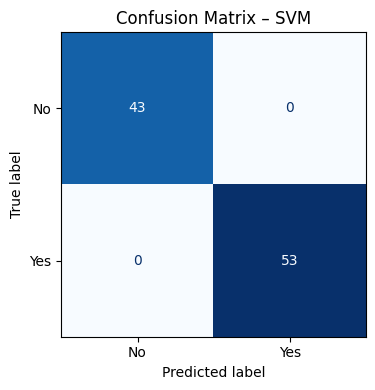


Model: KNN

Confusion Matrix:
[[43  0]
 [ 0 53]]

Classification Report:
              precision    recall  f1-score   support

          No     1.0000    1.0000    1.0000        43
         Yes     1.0000    1.0000    1.0000        53

    accuracy                         1.0000        96
   macro avg     1.0000    1.0000    1.0000        96
weighted avg     1.0000    1.0000    1.0000        96



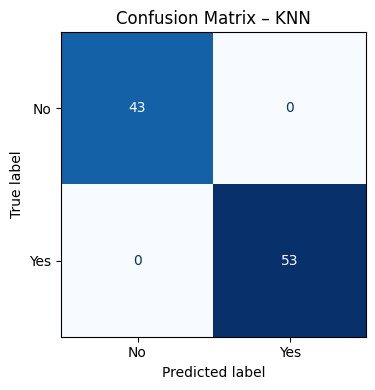


Model: Random Forest

Confusion Matrix:
[[43  0]
 [ 0 53]]

Classification Report:
              precision    recall  f1-score   support

          No     1.0000    1.0000    1.0000        43
         Yes     1.0000    1.0000    1.0000        53

    accuracy                         1.0000        96
   macro avg     1.0000    1.0000    1.0000        96
weighted avg     1.0000    1.0000    1.0000        96



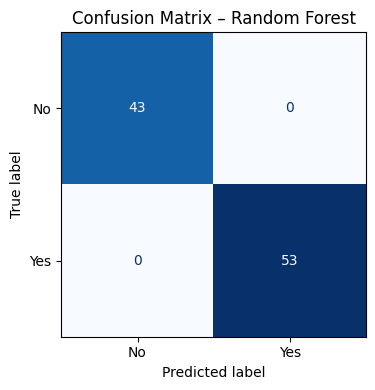


Model: MLP Neural Network

Confusion Matrix:
[[43  0]
 [ 0 53]]

Classification Report:
              precision    recall  f1-score   support

          No     1.0000    1.0000    1.0000        43
         Yes     1.0000    1.0000    1.0000        53

    accuracy                         1.0000        96
   macro avg     1.0000    1.0000    1.0000        96
weighted avg     1.0000    1.0000    1.0000        96



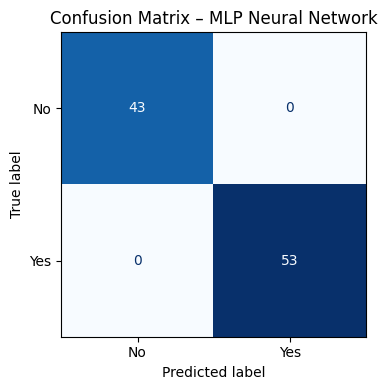

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

for model_name, y_pred in predictions.items():

    print(f"\n{'=' * 50}")
    print(f"Model: {model_name}")
    print(f"{'=' * 50}")

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["No", "Yes"],
            digits=4,
            zero_division=0
        )
    )

    fig, ax = plt.subplots(figsize=(5, 4))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    )

    display.plot(
        ax=ax,
        values_format="d",
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(f"Confusion Matrix – {model_name}")

    plt.tight_layout()
    plt.show()

## Group-Based Cross-Validation

I also ran five-fold `GroupKFold` validation on the training partition only, keeping source recordings together. All four models achieved accuracy and F1-score of 1.0000 on each fold. This provides an additional within-dataset check; it does not establish generalization to new speakers or prove segment-label alignment.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.base import clone

cv = GroupKFold(n_splits=5)

cv_results = []

for model_name, model in models.items():

    print(f"\nEvaluating {model_name}...")

    scores = cross_validate(
        clone(model),
        X_train,
        y_train,
        groups=train_groups,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1"
        },
        n_jobs=1
    )

    accuracy_scores = scores["test_accuracy"]
    f1_scores = scores["test_f1"]

    cv_results.append({
        "Model": model_name,
        "CV Accuracy Mean": np.mean(accuracy_scores),
        "CV Accuracy Std": np.std(accuracy_scores),
        "CV F1 Mean": np.mean(f1_scores),
        "CV F1 Std": np.std(f1_scores)
    })

    print("Accuracy per fold:", np.round(accuracy_scores, 4))
    print("F1 per fold:", np.round(f1_scores, 4))

cv_results_df = pd.DataFrame(cv_results)

print("\nCross-Validation Summary:")
print(cv_results_df.to_string(index=False))


Evaluating SVM...
Accuracy per fold: [1. 1. 1. 1. 1.]
F1 per fold: [1. 1. 1. 1. 1.]

Evaluating KNN...
Accuracy per fold: [1. 1. 1. 1. 1.]
F1 per fold: [1. 1. 1. 1. 1.]

Evaluating Random Forest...
Accuracy per fold: [1. 1. 1. 1. 1.]
F1 per fold: [1. 1. 1. 1. 1.]

Evaluating MLP Neural Network...
Accuracy per fold: [1. 1. 1. 1. 1.]
F1 per fold: [1. 1. 1. 1. 1.]

Cross-Validation Summary:
             Model  CV Accuracy Mean  CV Accuracy Std  CV F1 Mean  CV F1 Std
               SVM               1.0              0.0         1.0        0.0
               KNN               1.0              0.0         1.0        0.0
     Random Forest               1.0              0.0         1.0        0.0
MLP Neural Network               1.0              0.0         1.0        0.0


## Results and Discussion

I trained four classifiers on the same 32-dimensional acoustic representation. The held-out test set contained 43 No and 53 Yes samples, and each classifier correctly predicted all 96 samples. Their confusion matrices were identical, with no test-set errors. Five-fold group-based cross-validation on training recordings also returned perfect scores for all four models. Therefore, the experiment did not identify a single most accurate model.

KNN had the shortest measured `fit` time in this run, but fitting time alone is not a fair comparison of deployment cost because KNN performs more of its computation during prediction. The run times are environment-dependent.

I used automatic energy-based segmentation rather than verified word-level annotations. Although 59 recordings produced the expected eight regions, the labels for every extracted word have not been manually checked. Recording 21 was excluded because only seven regions were detected. The dataset is small and contains one speaker, so these results cannot establish accuracy for new speakers or noisy settings. The perfect scores should be interpreted as results for this particular dataset and evaluation procedure, not universal classifier performance.

## Conclusion

I used TorchAudio's YESNO dataset to prepare speech segments, extract acoustic features, and compare SVM, KNN, Random Forest, and an MLP neural network. All four models achieved an accuracy and F1-score of 1.0000 on the held-out test recordings. Group-based splitting avoided sharing source recordings between training and testing. The main limitation is that automatic word segmentation and label alignment were not fully verified, while the dataset contains only one speaker. Future evaluation would benefit from independently checked word boundaries and additional speakers.